# Step 5.2: Occlusion

Inference only. The Step 4 checkpoints are reloaded and never modified, and Step 5.0 has confirmed that the reload reproduces the clean baseline.

**In the paper.** The occlusion table (Sweep B with the M1 fill, Section 5.2.9), the scan that locates H$\beta$ and the profile-minimum control (Sections 5.2.5 and 5.2.6), and the signed bias by branch. Sweep C (the M2 and M3 fills) is an additional control kept for completeness and is not reported in the paper.

**The perturbation.** A window of $W$ pixels is erased. Three fills are defined, and the difference between them is the point of the experiment rather than an implementation detail.

| Code   | Fill                                                            | What it is                                      | Role                |
|--------|-----------------------------------------------------------------|-------------------------------------------------|---------------------|
| **M1** | linear interpolation between the two pixels bounding the window | information removed, still in distribution      | **primary**         |
| M2     | constant 1.0                                                    | information removed, mildly out of distribution | control             |
| M3     | constant 0.0                                                    | a fully saturated absorption trough injected    | separate experiment |

M1 is primary because it is what the Step 2 pipeline itself does to unusable pixels: they are dropped from the interpolation input and the resampled value is recovered from usable neighbours. An M1 window is therefore exactly what the model would see if a real stretch of spectrum were damaged and passed through the pipeline. Filling with zero is not information removal at all — on a continuum normalised to 1.0 it injects a 100%-deep absorption feature that never occurs in training — so it is run as its own experiment under its own name rather than as the definition of masking.

**The M1/M3 pair is the counterpart of the $C = 1$ / $C = 5$ pair of Step 5.1.** There, an amplitude control separated information loss from outlier magnitude, and information loss turned out to account for only 5% of the damage. Here the same logic separates information loss from out-of-distribution *structure*: M1 and M3 destroy identical information, so their difference is the distribution-shift term.

**Three sweeps.**

*Sweep A — a sliding scan* that locates, empirically, the regions each model depends on. The target of the targeted-masking branch is measured rather than assumed: Hα peaks near 9500 K, just outside the 9000 K ceiling of this catalogue, and is weak across the G and K dwarfs that dominate the sample, so an a priori choice of Hα is not safe.

*Sweep B — window width* $W \in \{2, 5, 10, 20, 50, 100\}$ at four branches: the measured target (which turns out to be H$\beta$), Hα and Mg b as named controls, and a per-spectrum random position.

*Sweep C — fill variant* M1 / M2 / M3 at $W = 50$.

## 5.2.1 Configuration

The scan runs on a subset, since what is needed from it is the *shape* of the dependence profile rather than a precise value at each position. The width and fill sweeps run on the full test partition, so their degradations are directly comparable with Step 5.1.

As in Step 5.1, every model and seed sees the **identical** corrupted tensor at each level: the tensor is built once and pushed through all ten networks before the next one is generated.

In [1]:
import os
import json
import time
import math

import numpy as np
import pandas as pd
import h5py
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# ==========================================
# CONFIGURATION
# ==========================================
DATA_DIR    = 'data'
RESULTS_DIR = 'results'
CKPT_DIR    = 'checkpoints'
STEP52_DIR  = os.path.join(RESULTS_DIR, 'step52')

MODELS = ['Conv-Pool', 'Conv-Attn']
SEEDS  = [0, 1, 2, 3, 4]

BATCH_SIZE = 256

# ---- attack ------------------------------------------------------------------
ATTACK      = 'occlusion'
ATTACK_SEED = 52          # RNG stream for the perturbation, independent of model seeds

FILLS       = ['interp', 'continuum', 'zero']     # M1, M2, M3
FILL_LABEL  = {'interp': 'M1 interp', 'continuum': 'M2 continuum', 'zero': 'M3 zero'}

# sweep A: coarse sliding scan, then a fine scan to localise the peak
SCAN_WIDTH  = 50
SCAN_STRIDE = 50          # non-overlapping, 82 positions
SCAN_N      = 3000        # spectra used for the coarse scan

FINE_WIDTH  = 10          # narrow window: locates the feature centre sharply
FINE_STRIDE = 4
FINE_SPAN   = 60          # +/- pixels around the coarse argmax
FINE_N      = 1500

# sweep B: window width, at four branches
W_LEVELS    = [2, 5, 10, 20, 50, 100]
BRANCHES    = ['targeted', 'halpha', 'mgb', 'random']

# sweep C: fill variant, at this width
W_REF       = 50

CATASTROPHIC_K = 300.0    # same convention as Step 5.0 and 5.1

# metrics carried through from Step 5.0; the clean value of each is subtracted
# from its attacked counterpart within the same model and seed
METRIC_COLS = ['rmse_K', 'mae_K', 'bias_K', 'p99_abs_K', 'gross_fail_frac']

COLORS = {'Conv-Pool': '#0173B2', 'Conv-Attn': '#DE8F05'}

# ==========================================
# PLOT STYLE
# ==========================================
sns.set_theme(style='whitegrid')
plt.rcParams.update({
    'font.size': 11,
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'Liberation Serif', 'DejaVu Serif'],
    'mathtext.fontset': 'stix',
    'axes.titlesize': 13,
    'axes.labelsize': 12,
    'legend.fontsize': 10,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'figure.dpi': 130,
})

W_DOUBLE = 7.0

# ==========================================
# LOAD METADATA AND THE STEP 5.0 BASELINE
# ==========================================
import common
device = common.get_device()

os.makedirs(STEP52_DIR, exist_ok=True)

with open(os.path.join(DATA_DIR, 'preprocessing_meta.json')) as f:
    prep = json.load(f)
with open(os.path.join(RESULTS_DIR, 'step50_meta.json')) as f:
    meta50 = json.load(f)

TEFF_MIN    = prep['teff_min']
TEFF_RANGE  = prep['teff_range']
NOISE_FLOOR = meta50['label_noise_floor_K']
GRID        = prep['grid']
GRID_N      = GRID['seq_length']
REG_EDGES   = meta50['regime_edges_K']

assert meta50['gate_passed'], 'Step 5.0 integrity gate did not pass'
assert meta50['eval_batch_size'] == BATCH_SIZE, 'batch size differs from Step 5.0'

clean_metrics = pd.read_csv(os.path.join(RESULTS_DIR, 'step50_baseline_metrics.csv'))

print(f'Device   : {device}')
print(f'Sweep A  : sliding scan, W = {SCAN_WIDTH}, stride {SCAN_STRIDE}, '
      f'{SCAN_N} spectra')
print(f'Sweep B  : W in {W_LEVELS} at branches {BRANCHES}')
print(f'Sweep C  : fills {[FILL_LABEL[f] for f in FILLS]} at W = {W_REF}')

Device   : cpu
Sweep A  : sliding scan, W = 50, stride 50, 3000 spectra
Sweep B  : W in [2, 5, 10, 20, 50, 100] at branches ['targeted', 'halpha', 'mgb', 'random']
Sweep C  : fills ['M1 interp', 'M2 continuum', 'M3 zero'] at W = 50


## 5.2.2 Architectures

The two models are defined once, in `models.py`, and loaded through `common.py` exactly as in Step 5.0. The parity check halts the notebook if a definition has drifted from the one the checkpoints were written against.

In [2]:
from models import SharedStem, check_parameter_parity
import common

check_parameter_parity()


def load_model(model_name, seed):
    return common.load_model(model_name, seed, device, CKPT_DIR)


def predict(model, x, batch_size=BATCH_SIZE):
    """Forward a device-resident tensor; returns absolute temperatures in Kelvin."""
    return common.predict(model, x, TEFF_MIN, TEFF_RANGE, batch_size)


def metrics(pred_k, true_k):
    return common.metrics(pred_k, true_k, CATASTROPHIC_K)


Conv-Pool : 537,857 parameters
Conv-Attn : 540,161 parameters
difference: 2,304 (0.43%)


## 5.2.3 Test partition and wavelength grid

Rows are selected exactly as in Step 4a, 5.0 and 5.1.

Unlike the spike attack, occlusion has a wavelength scale, so the grid is reconstructed here and the diagnostic features are placed on it. On the logarithmic grid of Step 2 the pixel width in Ångström varies across the band while the width in velocity does not, so a window of fixed pixel width erases a **constant velocity interval everywhere** — the physically meaningful invariant for line shapes — and a varying wavelength interval.

> **Vacuum against air.** SDSS stores BOSS spectra on a **vacuum** wavelength scale and Step 2 read the wavelength array straight from the FITS files, so this grid is vacuum, while the line table below uses **air** wavelengths. The offset is about one pixel (1.8 Å or 1.07 pixels at Hα) and is visible in the data: the fine scan of Section 5.2.6 places the H$\beta$ peak one pixel from its catalogued air position. The targeted branch is centred on the measured peak and is unaffected. For the Hα and Mg b branches the offset is negligible at $W = 50$, the width reported in the paper, and should be borne in mind at $W \le 10$. Both positions are printed for Hα.

In [3]:
test_idx, X_test, y_true_k = common.load_test_split(DATA_DIR, GRID_N)
N_TEST = len(test_idx)
X_clean = torch.from_numpy(X_test).to(device)

regime = pd.cut(y_true_k, bins=REG_EDGES)
REG_LABELS = [str(c) for c in regime.categories]
regime_mask = {str(c): np.asarray(regime == c) for c in regime.categories}

assert not np.isnan(X_test).any(), 'NaN in the test tensor'

# --- wavelength grid ----------------------------------------------------------
GRID_LO, GRID_HI = GRID['wave_start'], GRID['wave_end']
DLOG10 = GRID['dlog10']
KMS_PER_PIXEL = GRID['km_s_per_pixel']
wavegrid = GRID_LO * (GRID_HI / GRID_LO) ** (np.arange(GRID_N) / (GRID_N - 1))
pixel_axis = np.arange(GRID_N)

def lam_to_pixel(lam):
    return float(np.interp(lam, wavegrid, pixel_axis))

LINES = {'Ca II K': 3933.7, 'H-delta': 4101.7, 'H-gamma': 4340.5, 'H-beta': 4861.3,
         'Mg b': 5175.0, 'Na D': 5893.0, 'H-alpha': 6562.8, 'TiO bandhead': 7055.0,
         'Ca II 8542': 8542.1}
HALPHA_PX = int(round(lam_to_pixel(6562.8)))
MGB_PX    = int(round(lam_to_pixel(5175.0)))
HBETA_PX  = int(round(lam_to_pixel(4861.3)))

line_table = pd.DataFrame([
    {'feature': k, 'lambda_air_A': v, 'pixel': round(lam_to_pixel(v), 1),
     'dlambda_A_per_px': round(v * np.log(10) * DLOG10, 3)}
    for k, v in LINES.items()]).sort_values('lambda_air_A').reset_index(drop=True)

print(f'test spectra : {N_TEST:,}')
print(f'grid         : {GRID_LO:.0f}-{GRID_HI:.0f} A, {GRID_N} points, '
      f'{KMS_PER_PIXEL:.2f} km/s per pixel')
print(f'H-alpha air    6562.80 A -> pixel {lam_to_pixel(6562.80):.1f}  (used: {HALPHA_PX})')
print(f'H-alpha vacuum 6564.61 A -> pixel {lam_to_pixel(6564.61):.1f}')
print(f'Mg b     air   5175.00 A -> pixel {lam_to_pixel(5175.0):.1f}  (used: {MGB_PX})')
print(f'H-beta   air   4861.30 A -> pixel {lam_to_pixel(4861.3):.1f}')
print()
print('window width in physical units:')
for W in W_LEVELS:
    print(f'  W = {W:3d} px = {W * KMS_PER_PIXEL:7.0f} km/s = '
          f'{W * wavegrid[0] * np.log(10) * DLOG10:6.1f} A (blue) .. '
          f'{W * wavegrid[-1] * np.log(10) * DLOG10:6.1f} A (red), '
          f'{W * 6562.8 * np.log(10) * DLOG10:6.1f} A at H-alpha')
display(line_table)

test spectra : 18,898
grid         : 3600-10300 A, 4096 points, 76.96 km/s per pixel
H-alpha air    6562.80 A -> pixel 2339.2  (used: 2339)
H-alpha vacuum 6564.61 A -> pixel 2340.3
Mg b     air   5175.00 A -> pixel 1413.7  (used: 1414)
H-beta   air   4861.30 A -> pixel 1170.1

window width in physical units:
  W =   2 px =     154 km/s =    1.8 A (blue) ..    5.3 A (red),    3.4 A at H-alpha
  W =   5 px =     385 km/s =    4.6 A (blue) ..   13.2 A (red),    8.4 A at H-alpha
  W =  10 px =     770 km/s =    9.2 A (blue) ..   26.4 A (red),   16.8 A at H-alpha
  W =  20 px =    1539 km/s =   18.5 A (blue) ..   52.9 A (red),   33.7 A at H-alpha
  W =  50 px =    3848 km/s =   46.2 A (blue) ..  132.2 A (red),   84.2 A at H-alpha
  W = 100 px =    7696 km/s =   92.4 A (blue) ..  264.4 A (red),  168.5 A at H-alpha


,feature,lambda_air_A,pixel,dlambda_A_per_px
0,Ca II K,3933.7,345.3,1.010
1,H-delta,4101.7,508.2,1.053
2,H-gamma,4340.5,728.7,1.114
3,H-beta,4861.3,1170.1,1.248
4,Mg b,5175.0,1413.7,1.328
5,Na D,5893.0,1919.8,1.513
6,H-alpha,6562.8,2339.2,1.685
7,TiO bandhead,7055.0,2620.9,1.811
8,Ca II 8542,8542.1,3366.0,2.193


## 5.2.4 The perturbation

One routine handles all three fills and both position modes. Positions are given as a per-spectrum vector of window starts, so a fixed target is simply a constant vector — the random branch and the targeted branch then travel identical code, and no separate path can drift.

The interpolation fill reads the two pixels immediately outside the window and lays a linear ramp between them. Where a window touches an edge, the ramp degenerates to holding the one available boundary value, which is the same thing the Step 2 resampler does at the blue edge.

The random branch draws a start uniformly over the full grid, subject only to the window fitting inside it. No region is excluded: the models were trained on all 4096 pixels, and that some regions carry less temperature information than others is part of what this experiment measures.

In [4]:
def occlude(x, starts, width, fill='interp'):
    L = x.shape[-1]
    n = x.shape[0]
    s = torch.as_tensor(starts, dtype=torch.long, device=x.device).clamp(0, L - width)
    assert s.shape == (n,), f'need one start per spectrum, got {tuple(s.shape)} for {n} rows'
    rows = torch.arange(n, device=x.device).unsqueeze(1)
    idx = s.unsqueeze(1) + torch.arange(width, device=x.device).unsqueeze(0)   # (N, W)

    out = x.clone()
    if fill == 'zero':
        out[rows, 0, idx] = 0.0
    elif fill == 'continuum':
        out[rows, 0, idx] = 1.0
    elif fill == 'interp':
        li = (s - 1).clamp(0, L - 1)
        ri = (s + width).clamp(0, L - 1)
        left = x[torch.arange(n, device=x.device), 0, li].unsqueeze(1)
        right = x[torch.arange(n, device=x.device), 0, ri].unsqueeze(1)
        t = torch.linspace(0, 1, width + 2, device=x.device,
                           dtype=x.dtype)[1:-1].unsqueeze(0)
        out[rows, 0, idx] = left * (1 - t) + right * t
    else:
        raise ValueError(f'unknown fill: {fill}')
    return out


def run_level(starts, width, fill):
    """Evaluate all ten networks on one corrupted tensor."""
    X_att = occlude(X_clean, starts, width, fill)
    out = np.empty((len(SEEDS), len(MODELS), N_TEST), dtype=np.float32)
    for si, seed in enumerate(SEEDS):
        for mi, m in enumerate(MODELS):
            model = load_model(m, seed)
            out[si, mi] = predict(model, X_att).astype(np.float32)
            del model
            if device.type == 'cuda':
                torch.cuda.empty_cache()
    del X_att
    return out


# --- sanity checks on the routine ---------------------------------------------
_ramp = torch.arange(GRID_N, dtype=torch.float32, device=device).repeat(4, 1).unsqueeze(1)
_st = torch.tensor([100, 500, 2339, 4000], device=device)
_o = occlude(_ramp, _st, 50, 'interp')
print(f'interp fill on a linear ramp: max |diff| = {(_o - _ramp).abs().max():.6f} '
      f'(should be 0 — a ramp is its own interpolation)')
_o0 = occlude(_ramp, _st, 50, 'zero')
print(f'zero fill changes exactly {(_o0 != _ramp).sum(dim=2).squeeze(1).tolist()} pixels '
      f'per row (expected 50 each)')
print(f'clean tensor untouched: {bool((_ramp == torch.arange(GRID_N, dtype=torch.float32, device=device).repeat(4, 1).unsqueeze(1)).all())}')
del _ramp, _st, _o, _o0

interp fill on a linear ramp: max |diff| = 0.000244 (should be 0 — a ramp is its own interpolation)
zero fill changes exactly [50, 50, 50, 50] pixels per row (expected 50 each)
clean tensor untouched: True


## 5.2.5 Sweep A — sliding scan

A window of `SCAN_WIDTH` pixels is stepped across the grid and the rise in RMSE recorded against its position. The quantity produced, written $S(\lambda)$, is purely behavioural — defined through the input–output relation alone — and is therefore one of the few attribution measures that may be compared directly between the two architectures, unlike attention weights or gradient maps.

It is run on a subset because what is needed is the shape of the profile, not a precise value at each of the 82 positions, and because the full-partition sweeps that follow are where the reported degradations come from.

In [5]:
scan_path = os.path.join(STEP52_DIR, 'scan.npz')

scan_starts = list(range(0, GRID_N - SCAN_WIDTH + 1, SCAN_STRIDE))
if scan_starts[-1] != GRID_N - SCAN_WIDTH:
    scan_starts.append(GRID_N - SCAN_WIDTH)
scan_centre = np.array([s + SCAN_WIDTH / 2 for s in scan_starts])
scan_lambda = np.interp(scan_centre, pixel_axis, wavegrid)

_rng = np.random.default_rng([ATTACK_SEED, 1])
scan_idx = np.sort(_rng.choice(N_TEST, min(SCAN_N, N_TEST), replace=False))
X_scan = X_clean[torch.from_numpy(scan_idx).to(device)]
y_scan = y_true_k[scan_idx]

# projected cost, measured rather than guessed
_m = load_model(MODELS[0], SEEDS[0])
_t0 = time.time(); predict(_m, X_scan); _t_scan = time.time() - _t0
_t0 = time.time(); predict(_m, X_clean); _t_full = time.time() - _t0
del _m
if device.type == 'cuda':
    torch.cuda.empty_cache()

n_fine = 2 * FINE_SPAN // FINE_STRIDE + 1
n_sweepB = len(W_LEVELS) * len(BRANCHES)
n_sweepC = len(BRANCHES) * (len(FILLS) - 1)          # M1 at W_REF comes from sweep B
print(f'scan positions : {len(scan_starts)} coarse on {len(scan_idx):,} spectra, '
      f'{n_fine} fine on {FINE_N:,}')
print(f'one pass       : {_t_scan:.1f} s (subset)   {_t_full:.1f} s (full)')
print(f'projected, if nothing is reusable:')
print(f'  coarse scan {_t_scan * len(scan_starts) * 10 * 1.4 / 60:5.0f} min')
print(f'  fine scan   {_t_scan * (FINE_N / SCAN_N) * n_fine * 10 * 1.4 / 60:5.0f} min')
print(f'  sweep B     {_t_full * n_sweepB * 10 * 1.4 / 60:5.0f} min '
      f'({n_sweepB} configurations)')
print(f'  sweep C     {_t_full * n_sweepC * 10 * 1.4 / 60:5.0f} min '
      f'({n_sweepC} configurations)')
print('Configurations already on disk at the right window position are skipped.')

scan positions : 82 coarse on 3,000 spectra, 31 fine on 1,500
one pass       : 2.1 s (subset)   17.3 s (full)
projected, if nothing is reusable:
  coarse scan    41 min
  fine scan       8 min
  sweep B        97 min (24 configurations)
  sweep C        32 min (8 configurations)
Configurations already on disk at the right window position are skipped.


In [6]:
if os.path.exists(scan_path):
    print(f'[skip] {scan_path}')
    _z = np.load(scan_path)
    S = {(m, int(s)): _z[f'{m}|{s}'] for m in MODELS for s in SEEDS}
else:
    S = {}
    for seed in SEEDS:
        for m in MODELS:
            t0 = time.time()
            model = load_model(m, seed)
            base = predict(model, X_scan)
            base_rmse = float(np.sqrt(np.mean((base - y_scan) ** 2)))

            prof = np.zeros(len(scan_starts))
            for j, s0 in enumerate(scan_starts):
                st = torch.full((len(scan_idx),), s0, dtype=torch.long, device=device)
                p = predict(model, occlude(X_scan, st, SCAN_WIDTH, 'interp'))
                prof[j] = float(np.sqrt(np.mean((p - y_scan) ** 2))) - base_rmse

            S[(m, seed)] = prof
            del model
            if device.type == 'cuda':
                torch.cuda.empty_cache()
            print(f'  {m:10s} seed {seed}  peak dRMSE {prof.max():6.2f} K  '
                  f'({time.time() - t0:.0f}s)')

    np.savez_compressed(scan_path,
                        **{f'{m}|{s}': S[(m, s)] for m in MODELS for s in SEEDS},
                        starts=np.array(scan_starts), centre=scan_centre,
                        lam=scan_lambda, sample_index=scan_idx)
    print(f'[saved] {scan_path}')

S_mean = {m: np.mean([S[(m, s)] for s in SEEDS], axis=0) for m in MODELS}
S_sd = {m: np.std([S[(m, s)] for s in SEEDS], axis=0, ddof=1) for m in MODELS}

  Conv-Pool  seed 0  peak dRMSE  90.06 K  (217s)
  Conv-Attn  seed 0  peak dRMSE  43.56 K  (358s)
  Conv-Pool  seed 1  peak dRMSE  94.82 K  (224s)
  Conv-Attn  seed 1  peak dRMSE  63.00 K  (344s)
  Conv-Pool  seed 2  peak dRMSE  83.52 K  (177s)
  Conv-Attn  seed 2  peak dRMSE  33.66 K  (290s)
  Conv-Pool  seed 3  peak dRMSE  79.47 K  (176s)
  Conv-Attn  seed 3  peak dRMSE  27.63 K  (309s)
  Conv-Pool  seed 4  peak dRMSE  76.83 K  (188s)
  Conv-Attn  seed 4  peak dRMSE  36.47 K  (309s)
[saved] results\step52\scan.npz


## 5.2.6 Target selection

Three positions are read off the profile and handed to the width sweep.

The **targeted** branch uses the argmax of the profile averaged over both architectures. A per-architecture target would make the attack asymmetric — each model hit at its own worst point — which measures something different and less interpretable; a common target keeps the comparison clean. Each model's own argmax is reported alongside, and if the two disagree that is itself worth stating.

The **Hα** branch is the a priori choice, retained as a named control so the assumption can be tested rather than quietly replaced. Its rank in the profile answers directly whether it would have held.

The **argmin** is reported as a reference point: masking the least load-bearing region should cost almost nothing, and if it does not, a distribution-shift term is leaking into the measurement even under the M1 fill.

In [7]:
S_avg = np.mean([S_mean[m] for m in MODELS], axis=0)
j_max, j_min = int(np.argmax(S_avg)), int(np.argmin(S_avg))
TARGET_PX_COARSE = int(scan_centre[j_max])
TARGET_PX = TARGET_PX_COARSE
ARGMIN_PX = int(scan_centre[j_min])

j_ha = int(np.argmin(np.abs(scan_centre - HALPHA_PX)))
rank_ha = int((S_avg > S_avg[j_ha]).sum()) + 1

targets = {
    'targeted': {'pixel': TARGET_PX, 'lambda_A': round(float(scan_lambda[j_max]), 1),
                 'dRMSE_K': round(float(S_avg[j_max]), 3)},
    'argmin':   {'pixel': ARGMIN_PX, 'lambda_A': round(float(scan_lambda[j_min]), 1),
                 'dRMSE_K': round(float(S_avg[j_min]), 3)},
    'halpha':   {'pixel': HALPHA_PX, 'lambda_A': 6562.8,
                 'dRMSE_K': round(float(S_avg[j_ha]), 3),
                 'rank': rank_ha, 'of': len(scan_starts)},
}
for m in MODELS:
    jm = int(np.argmax(S_mean[m]))
    targets[f'argmax_{m}'] = {'pixel': int(scan_centre[jm]),
                              'lambda_A': round(float(scan_lambda[jm]), 1),
                              'dRMSE_K': round(float(S_mean[m][jm]), 3)}

print(f"targeted : pixel {TARGET_PX:5d}  {targets['targeted']['lambda_A']:8.1f} A   "
      f"dRMSE {targets['targeted']['dRMSE_K']:+7.2f} K")
print(f"argmin   : pixel {ARGMIN_PX:5d}  {targets['argmin']['lambda_A']:8.1f} A   "
      f"dRMSE {targets['argmin']['dRMSE_K']:+7.2f} K")
print(f"H-alpha  : pixel {HALPHA_PX:5d}  {6562.8:8.1f} A   "
      f"dRMSE {targets['halpha']['dRMSE_K']:+7.2f} K   "
      f"rank {rank_ha} of {len(scan_starts)}")
print()
for m in MODELS:
    t = targets[f'argmax_{m}']
    print(f"  own argmax {m:10s}: pixel {t['pixel']:5d}  {t['lambda_A']:8.1f} A")
agree = targets['argmax_Conv-Pool']['pixel'] == targets['argmax_Conv-Attn']['pixel']
print(f"  the two architectures {'agree' if agree else 'DISAGREE'} on their worst window")

with open(os.path.join(RESULTS_DIR, 'step52_targets.json'), 'w') as f:
    json.dump(targets, f, indent=2)

targeted : pixel  1175    4867.4 A   dRMSE  +60.73 K
argmin   : pixel  2025    6054.3 A   dRMSE   -0.03 K
H-alpha  : pixel  2339    6562.8 A   dRMSE  +30.03 K   rank 2 of 82

  own argmax Conv-Pool : pixel  1175    4867.4 A
  own argmax Conv-Attn : pixel  1175    4867.4 A
  the two architectures agree on their worst window


### Fine scan — localising the peak

The coarse scan steps in units of `SCAN_STRIDE`, so its argmax is quantised to the grid of window centres: it can be off by up to half a stride from the true centre of the sensitive feature. That is harmless at $W = 50$ and not harmless at $W = 2$, where a five-pixel error would place the window beside the line rather than on it.

A narrow window is stepped finely around the coarse argmax to fix the centre properly. The narrow window is what makes this sharp: a 50-pixel window smooths the profile over its own width, whereas a 10-pixel one resolves the feature.

The catalogued position of the nearest diagnostic line is printed alongside. If the two agree, the model's sensitivity peak sits on the line itself; if they differ by more than a couple of pixels, that gap is worth noting, since it would mean the model keys on the wing rather than the core.

In [8]:
fine_path = os.path.join(STEP52_DIR, 'scan_fine.npz')
fine_centres = np.arange(TARGET_PX_COARSE - FINE_SPAN, TARGET_PX_COARSE + FINE_SPAN + 1,
                         FINE_STRIDE)
fine_centres = fine_centres[(fine_centres >= FINE_WIDTH) &
                            (fine_centres < GRID_N - FINE_WIDTH)]

_rng = np.random.default_rng([ATTACK_SEED, 2])
fine_idx = np.sort(_rng.choice(N_TEST, min(FINE_N, N_TEST), replace=False))
X_fine = X_clean[torch.from_numpy(fine_idx).to(device)]
y_fine = y_true_k[fine_idx]

if os.path.exists(fine_path):
    print(f'[skip] {fine_path}')
    _z = np.load(fine_path)
    F = {(m, int(sd)): _z[f'{m}|{sd}'] for m in MODELS for sd in SEEDS}
    fine_centres = _z['centres']
else:
    F = {}
    for seed in SEEDS:
        for m in MODELS:
            t0 = time.time()
            model = load_model(m, seed)
            base = predict(model, X_fine)
            base_rmse = float(np.sqrt(np.mean((base - y_fine) ** 2)))
            prof = np.zeros(len(fine_centres))
            for j, c in enumerate(fine_centres):
                st = torch.full((len(fine_idx),), int(c - FINE_WIDTH // 2),
                                dtype=torch.long, device=device)
                p = predict(model, occlude(X_fine, st, FINE_WIDTH, 'interp'))
                prof[j] = float(np.sqrt(np.mean((p - y_fine) ** 2))) - base_rmse
            F[(m, seed)] = prof
            del model
            if device.type == 'cuda':
                torch.cuda.empty_cache()
            print(f'  {m:10s} seed {seed}  peak {prof.max():6.2f} K at pixel '
                  f'{int(fine_centres[int(np.argmax(prof))])}  ({time.time() - t0:.0f}s)')
    np.savez_compressed(fine_path, centres=fine_centres,
                        **{f'{m}|{sd}': F[(m, sd)] for m in MODELS for sd in SEEDS})
    print(f'[saved] {fine_path}')

F_avg = np.mean([np.mean([F[(m, sd)] for sd in SEEDS], axis=0) for m in MODELS], axis=0)
TARGET_PX = int(fine_centres[int(np.argmax(F_avg))])

print(f'\ncoarse argmax : pixel {TARGET_PX_COARSE}')
print(f'fine argmax   : pixel {TARGET_PX}   '
      f'({np.interp(TARGET_PX, pixel_axis, wavegrid):.1f} A)')
print(f'H-beta        : pixel {HBETA_PX}   (4861.3 A)   '
      f'offset {TARGET_PX - HBETA_PX:+d} px')
targets['targeted']['pixel'] = TARGET_PX
targets['targeted']['lambda_A'] = round(float(np.interp(TARGET_PX, pixel_axis, wavegrid)), 1)
targets['targeted']['located_by'] = f'fine scan, W = {FINE_WIDTH}, stride {FINE_STRIDE}'
targets['mgb'] = {'pixel': MGB_PX, 'lambda_A': 5175.0}
with open(os.path.join(RESULTS_DIR, 'step52_targets.json'), 'w') as f:
    json.dump(targets, f, indent=2)

  Conv-Pool  seed 0  peak  58.82 K at pixel 1171  (45s)
  Conv-Attn  seed 0  peak  36.88 K at pixel 1171  (61s)
  Conv-Pool  seed 1  peak  46.98 K at pixel 1171  (36s)
  Conv-Attn  seed 1  peak  39.32 K at pixel 1171  (60s)
  Conv-Pool  seed 2  peak  48.83 K at pixel 1171  (36s)
  Conv-Attn  seed 2  peak  37.78 K at pixel 1171  (59s)
  Conv-Pool  seed 3  peak  53.97 K at pixel 1171  (36s)
  Conv-Attn  seed 3  peak  17.71 K at pixel 1171  (59s)
  Conv-Pool  seed 4  peak  50.01 K at pixel 1171  (36s)
  Conv-Attn  seed 4  peak  19.62 K at pixel 1171  (59s)
[saved] results\step52\scan_fine.npz

coarse argmax : pixel 1175
fine argmax   : pixel 1171   (4862.4 A)
H-beta        : pixel 1170   (4861.3 A)   offset +1 px


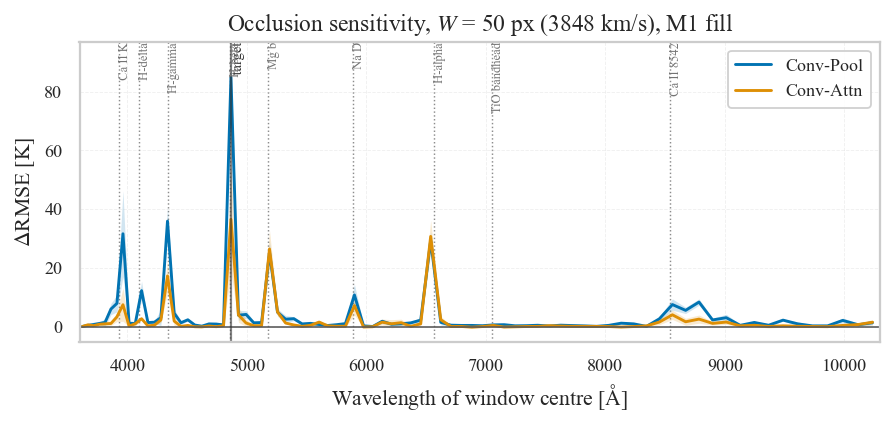

In [9]:
fig, ax = plt.subplots(figsize=(W_DOUBLE, 3.4))
for m in MODELS:
    mu, sd = S_mean[m], S_sd[m]
    ax.plot(scan_lambda, mu, color=COLORS[m], lw=1.6, label=m)
    ax.fill_between(scan_lambda, mu - sd, mu + sd, color=COLORS[m], alpha=0.18, lw=0)
ax.axhline(0, color='0.35', lw=0.9)
ax.axvline(scan_lambda[j_max], color='0.2', ls='-', lw=1.2, alpha=0.6)
ax.text(scan_lambda[j_max], ax.get_ylim()[1], ' target', rotation=90, va='top',
        ha='left', fontsize=8, color='0.2')
for name, lam in LINES.items():
    ax.axvline(lam, color='0.55', ls=':', lw=0.8, zorder=0)
    ax.text(lam, ax.get_ylim()[1], f' {name}', rotation=90, va='top', ha='left',
            fontsize=7, color='0.45')
ax.set_xlabel(r'Wavelength of window centre [$\mathrm{\AA}$]')
ax.set_ylabel(r'$\Delta$RMSE [K]')
ax.set_title(f'Occlusion sensitivity, $W$ = {SCAN_WIDTH} px '
             f'({SCAN_WIDTH * KMS_PER_PIXEL:.0f} km/s), M1 fill')
ax.set_xlim(wavegrid[0], wavegrid[-1])
ax.legend(loc='upper right', framealpha=0.92)
ax.grid(True, ls='--', alpha=0.3, lw=0.5)
plt.tight_layout()
plt.show()

## 5.2.7 Sweep B — window width

Five widths at three branches, M1 fill throughout, on the full test partition. The targeted and Hα branches place the same window in every spectrum; the random branch draws a fresh start per spectrum from a stream seeded on `(ATTACK_SEED, W)`, so it is reproducible and shared by all ten networks.

Windows are specified by their centre and converted to a start, so that a wider window grows symmetrically around the target rather than drifting off it.

In [10]:
CENTRE = {'targeted': None, 'halpha': HALPHA_PX, 'mgb': MGB_PX, 'random': None}
CENTRE['targeted'] = TARGET_PX          # set after the fine scan


def starts_for(branch, W):
    """Per-spectrum window starts for a branch at width W."""
    if branch == 'random':
        rng = np.random.default_rng([ATTACK_SEED, 7, W])
        return rng.integers(0, GRID_N - W + 1, size=N_TEST)
    c = CENTRE[branch]
    if c is None:
        raise ValueError(branch)
    return np.full(N_TEST, int(c - W // 2), dtype=np.int64)


def path_B(branch, W):
    return os.path.join(STEP52_DIR, f'B_{branch}_W{W:03d}.npz')


def is_current(path, branch, W):
    if not os.path.exists(path):
        return False
    if branch == 'random':
        return True                     # positions come from a fixed seed
    want = int(CENTRE[branch] - W // 2)
    return int(np.load(path)['starts'][0]) == want


for W in W_LEVELS:
    for branch in BRANCHES:
        if is_current(path_B(branch, W), branch, W):
            print(f'[skip] {branch:9s} W = {W:3d}')
            continue
        t0 = time.time()
        st = starts_for(branch, W)
        preds = run_level(st, W, 'interp')
        np.savez_compressed(path_B(branch, W), preds=preds,
                            starts=st.astype(np.int32), W=W, branch=branch,
                            fill='interp', seeds=np.array(SEEDS),
                            models=np.array(MODELS), attack_seed=ATTACK_SEED)
        rmse = np.sqrt(((preds - y_true_k[None, None, :]) ** 2).mean(axis=-1))
        print(f'{branch:9s} W = {W:3d}   ' + '   '.join(
            f'{m} {rmse[:, mi].mean():7.2f} K' for mi, m in enumerate(MODELS))
            + f'   ({time.time() - t0:.0f}s)')

targeted  W =   2   Conv-Pool   82.68 K   Conv-Attn   83.04 K   (194s)
halpha    W =   2   Conv-Pool   81.18 K   Conv-Attn   81.77 K   (194s)
mgb       W =   2   Conv-Pool   81.19 K   Conv-Attn   82.09 K   (194s)
random    W =   2   Conv-Pool   81.09 K   Conv-Attn   81.72 K   (193s)
targeted  W =   5   Conv-Pool  103.93 K   Conv-Attn  100.50 K   (193s)
halpha    W =   5   Conv-Pool   92.31 K   Conv-Attn   92.28 K   (193s)
mgb       W =   5   Conv-Pool   82.43 K   Conv-Attn   83.85 K   (193s)
random    W =   5   Conv-Pool   81.23 K   Conv-Attn   81.88 K   (195s)
targeted  W =  10   Conv-Pool  133.36 K   Conv-Attn  110.06 K   (192s)
halpha    W =  10   Conv-Pool  107.44 K   Conv-Attn  109.58 K   (193s)
mgb       W =  10   Conv-Pool   82.85 K   Conv-Attn   84.89 K   (193s)
random    W =  10   Conv-Pool   81.56 K   Conv-Attn   82.19 K   (194s)
targeted  W =  20   Conv-Pool  155.33 K   Conv-Attn  119.12 K   (193s)
halpha    W =  20   Conv-Pool  112.07 K   Conv-Attn  115.17 K   (192s)
mgb   

## 5.2.8 Sweep C — fill variant

The same three branches at $W = W_{\text{ref}}$, under the two remaining fills. Together with the M1 results already computed in Sweep B this gives the full three-way comparison.

M1 and M3 destroy identical information; their difference isolates the cost of the out-of-distribution structure that a zero fill injects. M2 sits between them: it removes the information and holds the continuum level, so it is in distribution in amplitude but not in shape, since a perfectly flat stretch of continuum does not occur naturally either.

In [11]:
def path_C(branch, fill):
    return os.path.join(STEP52_DIR, f'C_{branch}_{fill}_W{W_REF:03d}.npz')


for branch in BRANCHES:
    for fill in FILLS:
        if fill == 'interp':
            continue                      # already computed in sweep B at W_REF
        if is_current(path_C(branch, fill), branch, W_REF):
            print(f'[skip] {branch:9s} {FILL_LABEL[fill]}')
            continue
        t0 = time.time()
        st = starts_for(branch, W_REF)
        preds = run_level(st, W_REF, fill)
        np.savez_compressed(path_C(branch, fill), preds=preds,
                            starts=st.astype(np.int32), W=W_REF, branch=branch,
                            fill=fill, seeds=np.array(SEEDS),
                            models=np.array(MODELS), attack_seed=ATTACK_SEED)
        rmse = np.sqrt(((preds - y_true_k[None, None, :]) ** 2).mean(axis=-1))
        print(f'{branch:9s} {FILL_LABEL[fill]:14s}   ' + '   '.join(
            f'{m} {rmse[:, mi].mean():7.2f} K' for mi, m in enumerate(MODELS))
            + f'   ({time.time() - t0:.0f}s)')

targeted  M2 continuum     Conv-Pool  168.79 K   Conv-Attn  123.07 K   (193s)
targeted  M3 zero          Conv-Pool  124.77 K   Conv-Attn  129.47 K   (194s)
halpha    M2 continuum     Conv-Pool  110.75 K   Conv-Attn  110.09 K   (193s)
halpha    M3 zero          Conv-Pool  127.51 K   Conv-Attn  108.08 K   (193s)
mgb       M2 continuum     Conv-Pool  117.68 K   Conv-Attn  104.59 K   (194s)
mgb       M3 zero          Conv-Pool  130.31 K   Conv-Attn  116.10 K   (194s)
random    M2 continuum     Conv-Pool   93.70 K   Conv-Attn   88.28 K   (194s)
random    M3 zero          Conv-Pool  129.25 K   Conv-Attn   98.40 K   (193s)


## 5.2.9 Degradation

Every quantity is a difference against the Step 5.0 clean value, taken **within the same model and seed**, exactly as in Step 5.1.

In [12]:
def degradation_from(paths):
    """paths: list of (level_dict, filepath)."""
    rows = []
    for level, p in paths:
        preds = np.load(p)['preds']                 # (seeds, models, N_TEST)
        for si, seed in enumerate(SEEDS):
            for mi, m in enumerate(MODELS):
                pr = preds[si, mi].astype(np.float64)
                rows.append({**level, 'model': m, 'seed': seed, 'regime': 'all',
                             **metrics(pr, y_true_k)})
                for lab, sel in regime_mask.items():
                    rows.append({**level, 'model': m, 'seed': seed, 'regime': lab,
                                 **metrics(pr[sel], y_true_k[sel])})
    att = pd.DataFrame(rows)
    deg = att.merge(clean_metrics[['model', 'seed', 'regime'] + METRIC_COLS],
                    on=['model', 'seed', 'regime'], suffixes=('', '_clean'))
    for c in METRIC_COLS:
        deg['d_' + c] = deg[c] - deg[c + '_clean']
    return deg


deg_B = degradation_from([({'branch': b, 'W': W}, path_B(b, W))
                          for W in W_LEVELS for b in BRANCHES])
deg_B.to_csv(os.path.join(RESULTS_DIR, 'step52_degradation_width.csv'), index=False)

fill_paths = [({'branch': b, 'fill': 'interp'}, path_B(b, W_REF)) for b in BRANCHES]
fill_paths += [({'branch': b, 'fill': f}, path_C(b, f))
               for b in BRANCHES for f in FILLS if f != 'interp']
deg_C = degradation_from(fill_paths)
deg_C.to_csv(os.path.join(RESULTS_DIR, 'step52_degradation_fill.csv'), index=False)

ov_B = deg_B[deg_B.regime == 'all']
ov_C = deg_C[deg_C.regime == 'all']
print(f'{len(deg_B):,} rows in the width table, {len(deg_C):,} in the fill table')

2,400 rows in the width table, 1,200 in the fill table


In [13]:
piv = ov_B.pivot_table(index=['branch', 'W'], columns='model', values='d_rmse_K',
                       aggfunc=['mean', 'std'])
piv.columns = [f'{mod}_{ag}' for ag, mod in piv.columns]
piv['gap'] = piv['Conv-Attn_mean'] - piv['Conv-Pool_mean']
print('Sweep B — RMSE degradation by width and branch (K), M1 fill:')
print(piv.reindex(pd.MultiIndex.from_product([BRANCHES, W_LEVELS],
                                             names=['branch', 'W'])).round(2).to_string())

print('\nDoes knowing where to hit help? (targeted minus random, same width)')
for W in W_LEVELS:
    line = f'  W = {W:3d}  '
    for m in MODELS:
        t = ov_B[(ov_B.branch == 'targeted') & (ov_B.W == W) & (ov_B.model == m)]['d_rmse_K'].mean()
        r = ov_B[(ov_B.branch == 'random') & (ov_B.W == W) & (ov_B.model == m)]['d_rmse_K'].mean()
        line += f'{m} {t - r:+8.2f} K   '
    print(line)

print('\nWas H-alpha the right guess? (H-alpha minus random, same width)')
for W in W_LEVELS:
    line = f'  W = {W:3d}  '
    for m in MODELS:
        h = ov_B[(ov_B.branch == 'halpha') & (ov_B.W == W) & (ov_B.model == m)]['d_rmse_K'].mean()
        r = ov_B[(ov_B.branch == 'random') & (ov_B.W == W) & (ov_B.model == m)]['d_rmse_K'].mean()
        line += f'{m} {h - r:+8.2f} K   '
    print(line)

Sweep B — RMSE degradation by width and branch (K), M1 fill:
              Conv-Attn_mean  Conv-Pool_mean  Conv-Attn_std  Conv-Pool_std    gap
branch   W                                                                       
targeted 2              1.31            1.61           0.27           0.67  -0.29
         5             18.78           22.86           4.40           3.25  -4.08
         10            28.33           52.28           9.66           4.15 -23.95
         20            37.39           74.26          17.22          10.93 -36.86
         50            36.71           82.91          19.02          10.19 -46.20
         100           36.56           82.67          19.29           6.89 -46.12
halpha   2              0.05            0.10           0.14           0.14  -0.06
         5             10.56           11.23           1.47           1.89  -0.67
         10            27.86           26.36           2.58           2.15   1.49
         20            33.44         

In [14]:
pic = ov_C.pivot_table(index=['branch', 'fill'], columns='model', values='d_rmse_K',
                       aggfunc=['mean', 'std'])
pic.columns = [f'{mod}_{ag}' for ag, mod in pic.columns]
print(f'Sweep C — RMSE degradation by fill at W = {W_REF} (K):')
print(pic.reindex(pd.MultiIndex.from_product([BRANCHES, FILLS],
                                             names=['branch', 'fill'])).round(2).to_string())

print('\nThe distribution-shift term: M3 (zero) minus M1 (interp), same window')
for b in BRANCHES:
    line = f'  {b:9s}  '
    for m in MODELS:
        z = ov_C[(ov_C.branch == b) & (ov_C.fill == 'zero') & (ov_C.model == m)]['d_rmse_K'].mean()
        i = ov_C[(ov_C.branch == b) & (ov_C.fill == 'interp') & (ov_C.model == m)]['d_rmse_K'].mean()
        share = 100 * (z - i) / z if abs(z) > 1e-9 else float('nan')
        line += f'{m} {z - i:+8.2f} K ({share:4.0f}% of M3)   '
    print(line)
print('\nM1 and M3 remove the same information, so their difference is the cost of the '
      'injected structure rather than of the loss. Compare with the C = 1 control of '
      'Step 5.1, where information loss accounted for 5% of the spike damage.')

Sweep C — RMSE degradation by fill at W = 50 (K):
                    Conv-Attn_mean  Conv-Pool_mean  Conv-Attn_std  Conv-Pool_std
branch   fill                                                                   
targeted interp              36.71           82.91          19.02          10.19
         continuum           41.35           87.71          21.65          19.43
         zero                47.74           43.70          28.13          17.27
halpha   interp              30.71           28.89           5.49           3.34
         continuum           28.36           29.68           3.43           2.04
         zero                26.35           46.44           6.24          38.74
mgb      interp              21.51           13.88           6.42           3.55
         continuum           22.87           36.61          10.46          13.83
         zero                34.38           49.24          19.13          23.05
random   interp               2.78            5.30         

In [15]:
tests = []
for b in BRANCHES:
    for W in W_LEVELS:
        sub = ov_B[(ov_B.branch == b) & (ov_B.W == W)]
        a = sub[sub.model == 'Conv-Pool'].sort_values('seed')['d_rmse_K'].values
        c = sub[sub.model == 'Conv-Attn'].sort_values('seed')['d_rmse_K'].values
        d = c - a
        t, p = stats.ttest_rel(c, a)
        tests.append({'branch': b, 'W': W, 'gap_K': float(d.mean()),
                      'sd_of_diff': float(d.std(ddof=1)),
                      'gap_over_sd': float(d.mean() / d.std(ddof=1)),
                      'p_paired_t': float(p)})
tests = pd.DataFrame(tests)
tests.to_csv(os.path.join(RESULTS_DIR, 'step52_paired_tests.csv'), index=False)
print(tests.round(4).to_string(index=False))
print('Exploratory except for the reference configuration (targeted, W = 50). With five '
      'seeds the Wilcoxon test cannot fall below p = 0.0625, so the paired t and the '
      'gap-to-scatter ratio are the informative columns.')

  branch   W    gap_K  sd_of_diff  gap_over_sd  p_paired_t
targeted   2  -0.2931      0.7115      -0.4119      0.4091
targeted   5  -4.0777      4.2186      -0.9666      0.0967
targeted  10 -23.9496     12.2274      -1.9587      0.0119
targeted  20 -36.8636     14.2189      -2.5926      0.0044
targeted  50 -46.1980     11.6609      -3.9618      0.0009
targeted 100 -46.1152     13.5932      -3.3925      0.0016
  halpha   2  -0.0591      0.0998      -0.5916      0.2564
  halpha   5  -0.6732      2.4101      -0.2793      0.5661
  halpha  10   1.4926      3.5056       0.4258      0.3950
  halpha  20   2.4420      5.9492       0.4105      0.4106
  halpha  50   1.8192      4.0155       0.4530      0.3683
  halpha 100  -2.3850      5.6681      -0.4208      0.4000
     mgb   2   0.2496      0.5685       0.4391      0.3818
     mgb   5   0.7675      1.3737       0.5587      0.2797
     mgb  10   1.3874      0.6895       2.0122      0.0108
     mgb  20   5.9250      4.5740       1.2954      0.04

In [16]:
print('Sweep B — RMSE degradation by regime, targeted branch (K):')
by_reg = (deg_B[(deg_B.branch == 'targeted') & (deg_B.regime != 'all')]
          .pivot_table(index='regime', columns=['model', 'W'], values='d_rmse_K',
                       aggfunc='mean'))
print(by_reg.reindex(REG_LABELS).round(1).to_string())
print('If the H-alpha branch shows an effect only in the hottest regimes and none '
      'elsewhere, that is a result rather than a failed experiment: H-alpha peaks near '
      '9500 K and is weak across the G and K dwarfs that dominate this sample.')

Sweep B — RMSE degradation by regime, targeted branch (K):
model        Conv-Attn                                  Conv-Pool                                  
W                  2     5     10     20     50     100       2     5      10     20     50     100
regime                                                                                             
(3500, 4000]      -0.0   0.2   0.2   -0.3   -0.0    0.7      -0.1   0.2    0.6    0.7    0.7    2.0
(4000, 4500]       0.6   7.0   5.2    3.3    6.5   10.8       0.0   4.3    4.3    2.0    7.7   27.7
(4500, 5000]      -0.1   4.4   6.7    4.7    9.1   11.9      -0.6   4.6    8.1    2.6   13.9   34.9
(5000, 5500]       1.3  17.2  20.2   18.7   19.8   19.8       0.8  11.5   16.9   14.2   20.8   26.8
(5500, 6000]       1.4  30.2  39.1   39.3   38.0   37.2       2.8  34.3   47.8   49.3   52.6   48.7
(6000, 6500]       2.8  25.7  37.4   40.8   41.4   40.4       3.7  40.1   66.7   76.5   84.9   80.8
(6500, 7000]       0.6  10.5  27.8   39.6

## 5.2.10 Figures

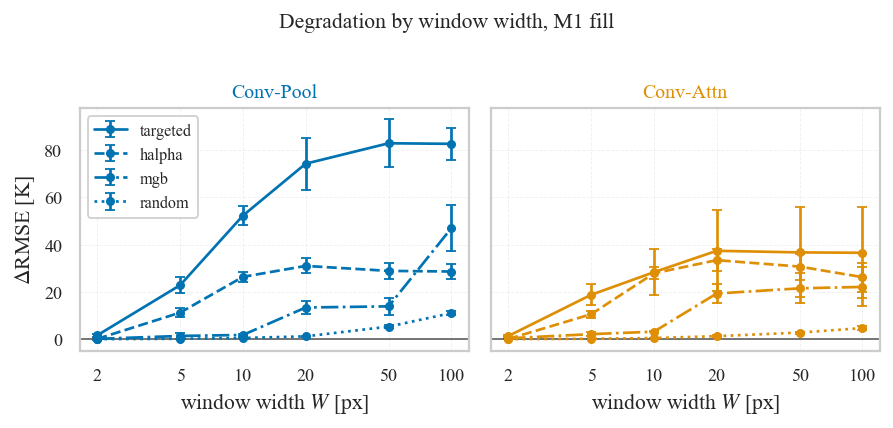

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(W_DOUBLE, 3.2), sharey=True)
STYLE = {'targeted': '-', 'halpha': '--', 'mgb': '-.', 'random': ':'}

for ax, m in zip(axes, MODELS):
    for b in BRANCHES:
        g = ov_B[(ov_B.model == m) & (ov_B.branch == b)].groupby('W')['d_rmse_K']
        ax.errorbar(g.mean().index, g.mean().values, yerr=g.std().values,
                    color=COLORS[m], ls=STYLE[b], marker='o', ms=4, lw=1.5,
                    capsize=3, label=b)
    ax.axhline(0, color='0.35', lw=0.9)
    ax.set_xscale('log')
    ax.set_xticks(W_LEVELS)
    ax.set_xticklabels(W_LEVELS)
    ax.set_xlabel('window width $W$ [px]')
    ax.set_title(m, color=COLORS[m], fontsize=11)
    ax.grid(True, ls='--', alpha=0.3, lw=0.5)

axes[0].set_ylabel(r'$\Delta$RMSE [K]')
axes[0].legend(fontsize=9, framealpha=0.92)
fig.suptitle('Degradation by window width, M1 fill', y=1.02, fontsize=12)
plt.tight_layout()
plt.show()

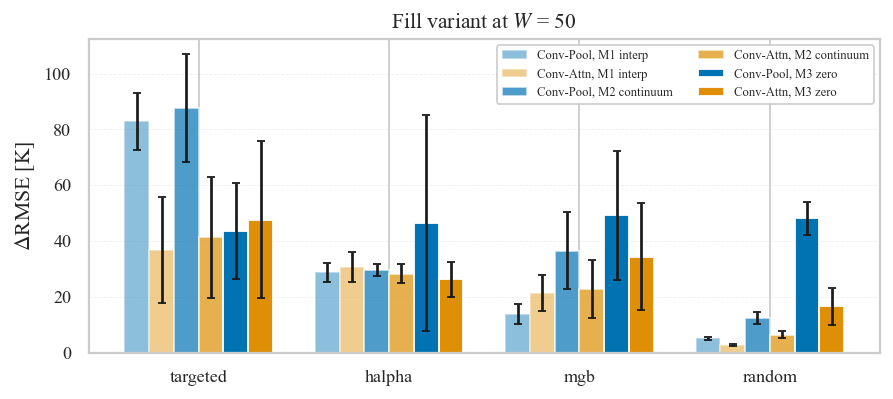

In [18]:
fig, ax = plt.subplots(figsize=(W_DOUBLE, 3.2))
xb = np.arange(len(BRANCHES))
w = 0.13

for fi, fill in enumerate(FILLS):
    for mi, m in enumerate(MODELS):
        vals = [ov_C[(ov_C.branch == b) & (ov_C.fill == fill) &
                     (ov_C.model == m)]['d_rmse_K'].mean() for b in BRANCHES]
        errs = [ov_C[(ov_C.branch == b) & (ov_C.fill == fill) &
                     (ov_C.model == m)]['d_rmse_K'].std() for b in BRANCHES]
        off = (fi * len(MODELS) + mi - 2.5) * w
        ax.bar(xb + off, vals, w, yerr=errs, capsize=2,
               color=COLORS[m], alpha=[0.45, 0.7, 1.0][fi],
               label=f'{m}, {FILL_LABEL[fill]}')

ax.set_xticks(xb)
ax.set_xticklabels(BRANCHES)
ax.set_ylabel(r'$\Delta$RMSE [K]')
ax.set_title(f'Fill variant at $W$ = {W_REF}', fontsize=12)
ax.legend(fontsize=7, ncol=2, framealpha=0.92)
ax.grid(True, axis='y', ls='--', alpha=0.3, lw=0.5)
plt.tight_layout()
plt.show()

## 5.2.11 Export

Dictionaries are built with explicit loops rather than comprehensions containing `DataFrame.query`, for the reason established in Step 5.0.

In [19]:
def summary(df, keys, key_names):
    out = {}
    for m in MODELS:
        per = {}
        for k in keys:
            sel = df['model'] == m
            for name, val in zip(key_names, k if isinstance(k, tuple) else (k,)):
                sel = sel & (df[name] == val)
            v = df[sel]['d_rmse_K']
            per['|'.join(str(x) for x in (k if isinstance(k, tuple) else (k,)))] = \
                [float(v.mean()), float(v.std())]
        out[m] = per
    return out


meta = {
    'step': '5.2',
    'attack': ATTACK,
    'description': 'a window of W pixels erased, under three fill conventions',
    'attack_seed': ATTACK_SEED,
    'n_test': int(N_TEST),
    'seeds': SEEDS,
    'models': MODELS,
    'eval_batch_size': BATCH_SIZE,
    'catastrophic_threshold_K': CATASTROPHIC_K,
    'fills': {'interp': 'linear ramp between the bounding pixels (M1, primary)',
              'continuum': 'constant 1.0 (M2)',
              'zero': 'constant 0.0 (M3, injected absorption artefact)'},
    'scan': {'width': SCAN_WIDTH, 'stride': SCAN_STRIDE,
             'n_positions': len(scan_starts), 'n_spectra': int(len(scan_idx)),
             'fine': {'width': FINE_WIDTH, 'stride': FINE_STRIDE, 'span': FINE_SPAN,
                      'n_spectra': int(FINE_N),
                      'coarse_argmax_px': int(TARGET_PX_COARSE),
                      'fine_argmax_px': int(TARGET_PX),
                      'h_beta_px': int(HBETA_PX)}},
    'branch_centres_px': {b: (None if b == 'random' else int(CENTRE[b]))
                          for b in BRANCHES},
    'targets': targets,
    'sweep_width': {'W_levels': W_LEVELS, 'branches': BRANCHES, 'fill': 'interp',
                    'd_rmse_K': summary(ov_B,
                                        [(b, W) for b in BRANCHES for W in W_LEVELS],
                                        ['branch', 'W'])},
    'sweep_fill': {'W': W_REF, 'branches': BRANCHES, 'fills': FILLS,
                   'd_rmse_K': summary(ov_C,
                                       [(b, f) for b in BRANCHES for f in FILLS],
                                       ['branch', 'fill'])},
    'grid': GRID,
    'halpha_pixel_air': HALPHA_PX,
    'mgb_pixel_air': MGB_PX,
    'wavelength_convention_note': (
        'the grid is most likely vacuum while the line table is air; the offset at '
        'H-alpha is 1.07 pixels, which matters at W = 10'),
}
with open(os.path.join(RESULTS_DIR, 'step52_meta.json'), 'w') as f:
    json.dump(meta, f, indent=2)

print('Written to results/:')
for fn in sorted(f for f in os.listdir(RESULTS_DIR) if f.startswith('step52')):
    print(f'  {fn:40s} {os.path.getsize(os.path.join(RESULTS_DIR, fn)) / 1024:7.1f} KB')
tot = sum(os.path.getsize(os.path.join(STEP52_DIR, f))
          for f in os.listdir(STEP52_DIR)) / 1024 ** 2
print(f'  step52/  (per-spectrum predictions and window positions)  {tot:.1f} MB')

# the exported summary must agree with the tables above
for m in MODELS:
    a = meta['sweep_width']['d_rmse_K'][m][f'targeted|{W_REF}'][0]
    b = float(ov_B[(ov_B.branch == 'targeted') & (ov_B.W == W_REF) &
                   (ov_B.model == m)]['d_rmse_K'].mean())
    assert abs(a - b) < 1e-9, f'exported summary disagrees with the table for {m}'
print('\nExported summary verified against the in-notebook tables.')

Written to results/:
  step52                                       8.0 KB
  step52_degradation_fill.csv                407.7 KB
  step52_degradation_width.csv               809.5 KB
  step52_meta.json                             9.5 KB
  step52_paired_tests.csv                      2.1 KB
  step52_targets.json                          0.6 KB
  step52/  (per-spectrum predictions and window positions)  19.7 MB

Exported summary verified against the in-notebook tables.


### Stored per-spectrum predictions

`results/step52/` holds, for every configuration, the prediction of every network on every spectrum together with the window positions that produced it, and `scan.npz` holds the per-seed dependence profiles, so any configuration can be re-analysed without re-running the attack.